In [ ]:
from pathlib import Path
from ndvi_kmeans import process_fields_ndvi_kmeans, train_kmeans_model
from ndvi__ndmi_downloader import download_clip_sentinel_ndvi_ndmi
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import rasterio

BOUNDARY_FILE = Path("test/fields.geojson")
NDVI_DIR = Path("test/ndvi")
OUT_DIR = Path("test/zones")
MODEL_PATH = OUT_DIR / "ndvi_kmeans_model.joblib"
START_DATES = ["2020-03-20", "2021-03-20", "2022-03-20"]
END_DATES = ["2020-06-30", "2021-06-30", "2022-06-30"]
N_SCENES = 8
N_CLUSTERS = 3

In [4]:
existing_tifs = sorted(NDVI_DIR.glob("*.tif")) if NDVI_DIR.exists() else []
if not existing_tifs:
    for start, end in zip(START_DATES, END_DATES):
        download_clip_sentinel_ndvi(
            boundary_file=BOUNDARY_FILE,
            start_date=start,
            end_date=end,
            out_dir=NDVI_DIR,
            max_cc=20,
            n_scenes=N_SCENES,
        )
else:
    print(f"Znaleziono {len(existing_tifs)} lokalnych scen NDVI w {NDVI_DIR}")

Znaleziono 23 lokalnych scen NDVI w test\ndvi


In [ ]:
model_training = train_kmeans_model(
    boundary_file=BOUNDARY_FILE,
    ndvi_dir=NDVI_DIR,
    model_path=MODEL_PATH,
)

,,polygons,total_area_ha,mean_ndvi_z
zone,zone_label,,,
1,slaba,113,154.440,-0.899
2,srednia,148,249.787,-0.059
3,mocna,132,245.195,0.729


,field_id,zone,zone_label,area_ha,ndvi_z,geometry
0,1,3,mocna,0.5203,0.8771,"POLYGON ((281252.15 535824.496, 281251.595 535..."
1,1,2,srednia,4.1321,-0.1389,"POLYGON ((281329.272 535770.121, 281319.285 53..."
2,2,1,slaba,0.4402,-1.0132,"POLYGON ((282814.016 535447.188, 282804.029 53..."
3,2,3,mocna,0.6303,0.7894,"POLYGON ((282626.48 535317.358, 282627.035 535..."
4,2,2,srednia,3.0315,-0.0189,"POLYGON ((282710.814 535212.493, 282700.827 53..."


In [11]:
zones_gdf = process_fields_ndvi_kmeans(
    boundary_file=BOUNDARY_FILE,
    ndvi_dir=NDVI_DIR,
    out_dir=OUT_DIR,
    model_path=MODEL_PATH,
    n_clusters=N_CLUSTERS,
    inner_buffer_m=10.0,
    min_area_ha=3.0,
    min_zone_area_ha=0.15,
    apply_majority_filter=True,
)

display(
    zones_gdf.groupby(["zone", "zone_label"])
    .agg(
        polygons=("area_ha", "count"),
        total_area_ha=("area_ha", "sum"),
        mean_ndvi_z=("ndvi_z", "mean"),
    )
    .round(3)
)
zones_gdf.head()

,,polygons,total_area_ha,mean_ndvi_z
zone,zone_label,,,
1,slaba,158,158.932,-0.925
2,srednia,198,246.115,-0.048
3,mocna,163,244.374,0.743


,field_id,zone,zone_label,area_ha,ndvi_z,geometry
0,1,1,slaba,0.1601,-1.1291,"POLYGON ((281208.874 535947.116, 281206.099 53..."
1,1,1,slaba,0.2201,-0.8004,"POLYGON ((281265.467 535883.864, 281264.912 53..."
2,1,3,mocna,0.2401,0.6442,"POLYGON ((281125.092 535881.646, 281124.537 53..."
3,1,3,mocna,0.5203,0.8771,"POLYGON ((281252.15 535824.496, 281251.595 535..."
4,1,2,srednia,3.5118,-0.1058,"POLYGON ((281340.369 535789.54, 281339.814 535..."


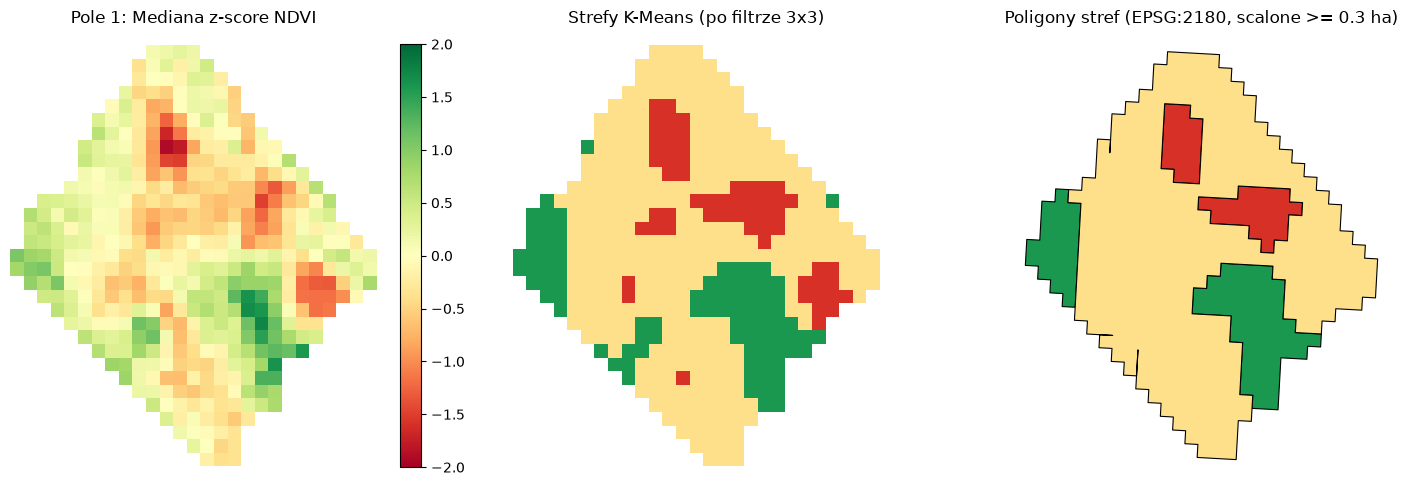

In [12]:
if not zones_gdf.empty:
    sample_field_id = zones_gdf["field_id"].iloc[0]
    field_polys = zones_gdf[zones_gdf["field_id"] == sample_field_id]

    ndvi_z_tif = OUT_DIR / "rasters" / f"field_{sample_field_id}_ndvi_z.tif"
    zones_tif = OUT_DIR / "rasters" / f"field_{sample_field_id}_zones.tif"

    with rasterio.open(ndvi_z_tif) as src_z, rasterio.open(zones_tif) as src_c:
        arr_z = src_z.read(1)
        arr_c = src_c.read(1).astype(float)
        arr_c[arr_c == 0] = np.nan

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    im0 = axes[0].imshow(arr_z, cmap="RdYlGn", vmin=-2, vmax=2)
    axes[0].set_title(f"Pole {sample_field_id}: Mediana z-score NDVI")
    plt.colorbar(im0, ax=axes[0], fraction=0.046)

    zone_cmap = ListedColormap(["#d73027", "#fee08b", "#1a9850"])
    axes[1].imshow(arr_c, cmap=zone_cmap, vmin=1, vmax=3, interpolation="nearest")
    axes[1].set_title("Strefy K-Means (po filtrze 3x3)")

    color_map = {1: "#d73027", 2: "#fee08b", 3: "#1a9850"}
    field_polys.plot(
        ax=axes[2],
        color=field_polys["zone"].map(color_map),
        edgecolor="black",
        linewidth=0.8,
    )
    axes[2].set_title("Poligony stref (EPSG:2180, scalone >= 0.3 ha)")

    for ax in axes:
        ax.set_axis_off()
    plt.tight_layout()
    plt.show()